In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random
%matplotlib inline

In [2]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0 # derivitive of the 'output', with respect to this Value object
        self._backward = lambda: None # by efault backward doesnt do anything (i.e for a leaf node)
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other): # self + other
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
          self.grad += 1.0 * out.grad
          other.grad += 1.0 * out.grad #plus is a distributor, out.grad gets copied to self and other

        out._backward = _backward
        return out

    def __sub__(self, other): # self - other
        return self + (-other)

    def __neg__(self): # -self
      return self * -1

    def __mul__(self, other): # self * other
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
          self.grad += other.data * out.grad
          other.grad+= self.data * out.grad

        out._backward = _backward

        return out

    #pow function (only support int/floats for other)
    def __pow__(self, other): # self ** other
      out = Value(self.data**other, (self, ), f'**{other}')

      def _backward():
        self.grad += other * (self.data ** (other - 1)) * out.grad

      out._backward = _backward
      return out

    def __rmul__(self, other): # other * self
      return self * other
    def __radd__(self,other):
      return self + other
    def __truediv__(self, other): # self / other
      return self * other**-1

    def tanh(self): # tanh(self)
      x = self.data
      t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
      out = Value(t, (self, ), 'tanh')

      def _backward():
        self.grad += (1 - t ** 2) * out.grad

      out._backward = _backward
      return out

    def exp(self): # e**self
      x = self.data
      out = Value(math.exp(x), (self, ), 'exp')

      def _backward():
        self.grad += out.data * out.grad

      out._backward = _backward
      return out

    def backward(self):
      topo = []
      visited = set()
      def build_topo(v):
        if v not in visited:
          visited.add(v)
          for child in v._prev:
            build_topo(child)
          topo.append(v)

      build_topo(self)

      self.grad = 1.0 # this is the output, and 1 is basecase (do/do = 1)
      for node in reversed(topo):
        node._backward()

In [3]:
a = Value(2.0)
b = Value(4.0)
a - b

Value(data=-2.0)

In [4]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        #for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is the result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)
    for n1,n2 in edges:
        #connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

In [6]:
!#inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')

#x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

o = n.tanh(); o.label = 'o'
o.backward()

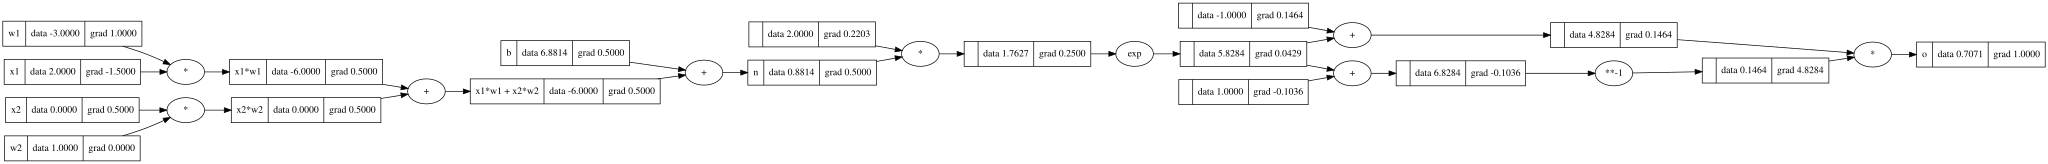

In [8]:
draw_dot(o)

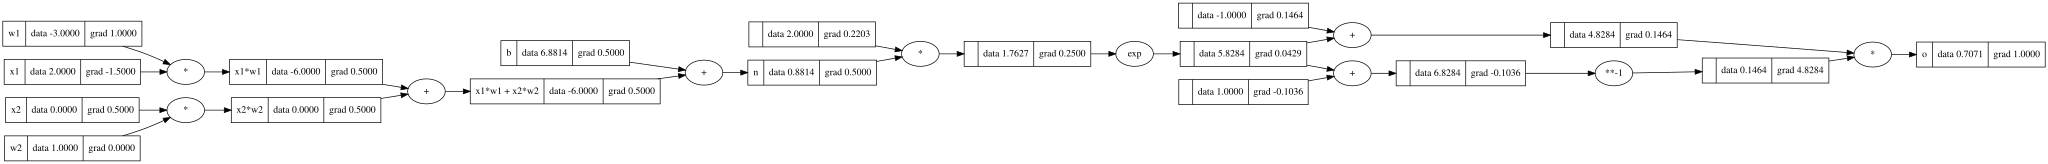

In [7]:
#inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')

#x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
# ---
e = (2*n).exp()
o = (e-1) / (e+1)
# ---
o.label = 'o'
o.backward()
draw_dot(o)

In [9]:
import torch

x1 = torch.Tensor([2.0]).double()               ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()               ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()              ; w1.requires_grad = True
w2 = torch.tensor([1.0]).double()               ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double() ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [ ]:
o

In [10]:
class Neuron:

  def __init__(self, nin): ## nin means number of inputs
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self, x): #__call__ means Neuron (x) -> return thing
    # w * x + b
    activation = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = activation.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]

class Layer: # gonna be one layer of a multi layer perceptron
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self,x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self,x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

In [11]:
x = [2, 3, -1]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=0.9815179485573865)

In [12]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

In [13]:
for k in range(200):
  # forward pass
  ypred = [n(x) for x in xs]
  loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

  for p in n.parameters():
    p.grad = 0.0
  #backward pass
  loss.backward()

  #update
  for p in n.parameters():
    p.data += -0.05 * p.grad #bc we want to minimize the loss, thats why its -0.01, we need to flip the vector

  print(k, loss.data)

0 7.593864715346245
1 7.3893013856721
2 6.938522338249772
3 5.7864813141544555
4 3.3169574912176683
5 1.987472733495991
6 1.5211755616560954
7 0.9893840828549618
8 0.6114096183316441
9 0.31429507391121597
10 0.22098963922011572
11 0.16745898445930635
12 0.13279857934983633
13 0.10927581197653446
14 0.09255610066639051
15 0.08017257731022823
16 0.07067556427705882
17 0.06317841359414586
18 0.05711636235294548
19 0.05211580960026813
20 0.047921088147996393
21 0.04435192482267747
22 0.04127782751843898
23 0.038602138151650645
24 0.03625179464901738
25 0.034170573179168905
26 0.03231451456734403
27 0.030648758369537885
28 0.02914530632770348
29 0.027781413052250323
30 0.026538408554948188
31 0.025400823579798944
32 0.024355730808775282
33 0.023392242337164536
34 0.022501121866720913
35 0.02167448220692906
36 0.020905546974583578
37 0.020188461141311273
38 0.019518139131373194
39 0.018890142061081514
40 0.018300577795669716
41 0.017746019020572983
42 0.017223435645866026
43 0.01673013869813

In [ ]:
ypred